# House Price Prediction
## Notebook 2 — Exploratory Data Analysis
**Author: Tinashe Clifford Makandise**

## 1. Purpose and boundaries
Explore the training data to understand sale prices, candidate predictors, missingness and unusual observations. This follows Notebook 1 and prepares decisions for Notebook 3. We do not open the test set, fit prediction models, impute values or remove records here. Relationships are descriptive associations, not causal effects.

### Questions
- How skewed are prices?
- How do area, location, quality, age and garage capacity relate to price?
- Which inputs overlap or have sparse coverage?
- Which records and missing-value meanings need investigation?

### Prerequisites
Run Notebook 1 first. It creates `data/processed/train.csv` and `reports/data_manifest.json`. Save this file alongside Notebook 1 in `notebooks/`. Install once if needed: `%pip install pandas numpy matplotlib seaborn`. The original dataset and attribution are documented in Notebook 1.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = PROJECT_ROOT / "data/processed/train.csv"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
if not TRAIN_PATH.is_file():
    raise FileNotFoundError("Run Notebook 1 first to create data/processed/train.csv.")
train = pd.read_csv(TRAIN_PATH, keep_default_na=False, na_values=[""])
manifest = json.loads((REPORTS_DIR / "data_manifest.json").read_text(encoding="utf-8"))
assert len(train) == manifest["train_rows"]
assert train["PID"].is_unique
assert set(train["PID"].astype(int)) == set(manifest["train_pids"])
assert not set(train["PID"].astype(int)).intersection(manifest["test_pids"])
assert train["SalePrice"].gt(0).all()
eda = train.copy()
eda["AgeAtSale"] = eda["Yr Sold"] - eda["Year Built"]
eda["LogSalePrice"] = np.log1p(eda["SalePrice"])
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
def finish_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
print(f"Verified training partition: {len(eda):,} properties. Test data not loaded.")

Verified training partition: 2,344 properties. Test data not loaded.


## 2. Sale-price distribution
Compare prices in original USD with `log1p(price)`. A log transform compresses high values and is a candidate target transformation for later cross-validation, not a decision made from appearance alone. Evaluation must still report errors in USD. The median is resistant to extreme prices; the mean is more sensitive.

                 USD
count    2344.000000
mean   178582.207765
std     77125.072713
min     12789.000000
5%      87507.500000
25%    129000.000000
50%    160000.000000
75%    210000.000000
95%    324850.000000
max    755000.000000
Raw skewness: 1.75
Log1p skewness: -0.09


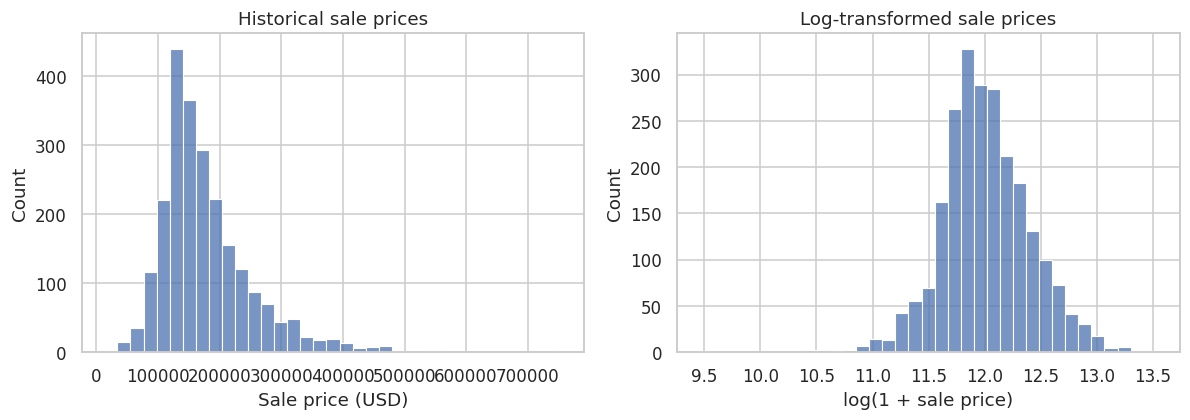

In [2]:
price_summary = eda["SalePrice"].describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("USD")
display(price_summary)
print(f"Raw skewness: {eda['SalePrice'].skew():.2f}")
print(f"Log1p skewness: {eda['LogSalePrice'].skew():.2f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=eda, x="SalePrice", bins=35, ax=axes[0])
axes[0].set(title="Historical sale prices", xlabel="Sale price (USD)")
sns.histplot(data=eda, x="LogSalePrice", bins=35, ax=axes[1])
axes[1].set(title="Log-transformed sale prices", xlabel="log(1 + sale price)")
finish_figure("02_price_distribution")

## 3. Area and property age
Living area is above-ground floor area in square feet, not land area. Age is measured at the recorded sale. These scatterplots show spread and unusual combinations as well as overall trends. Older properties can command high prices owing to location, renovation or other characteristics.

Gr Liv Area    0.698
AgeAtSale     -0.546
Name: SalePrice, dtype: float64


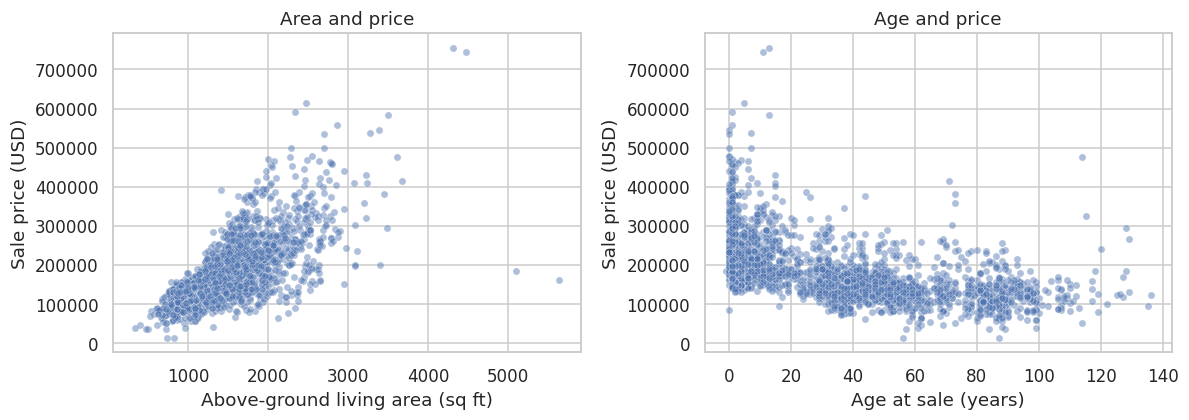

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=eda, x="Gr Liv Area", y="SalePrice", alpha=.45, s=22, ax=axes[0])
axes[0].set(xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD)", title="Area and price")
sns.scatterplot(data=eda, x="AgeAtSale", y="SalePrice", alpha=.45, s=22, ax=axes[1])
axes[1].set(xlabel="Age at sale (years)", ylabel="Sale price (USD)", title="Age and price")
finish_figure("02_area_age")
print(eda[["Gr Liv Area", "AgeAtSale", "SalePrice"]].corr()["SalePrice"].drop("SalePrice").round(3))

## 4. Quality, condition and garage capacity
Boxplots display the median, middle 50% and tails for each group. Points beyond whiskers are not necessarily errors. Counts below each analysis help identify small groups. These are unadjusted comparisons: houses can differ simultaneously in area, location and quality.


Overall Qual: counts and median prices
              count    median
Overall Qual                 
1                 4   50150.0
2                10   50750.0
3                30   80250.0
4               177  105000.0
5               675  133000.0
6               613  160000.0
7               465  200000.0
8               267  263550.0
9                81  350000.0
10               22  453475.0

Overall Cond: counts and median prices
              count    median
Overall Cond                 
1                 5   62500.0
2                 8   81750.0
3                36   88250.0
4                78  122500.0
5              1305  184000.0
6               448  142500.0
7               317  140000.0
8               112  139250.0
9                35  161000.0

Garage Cars: counts and median prices
             count    median
Garage Cars                 
0.0            120   99800.0
1.0            651  127000.0
2.0           1287  176500.0
3.0            272  298068.0
4.0             1

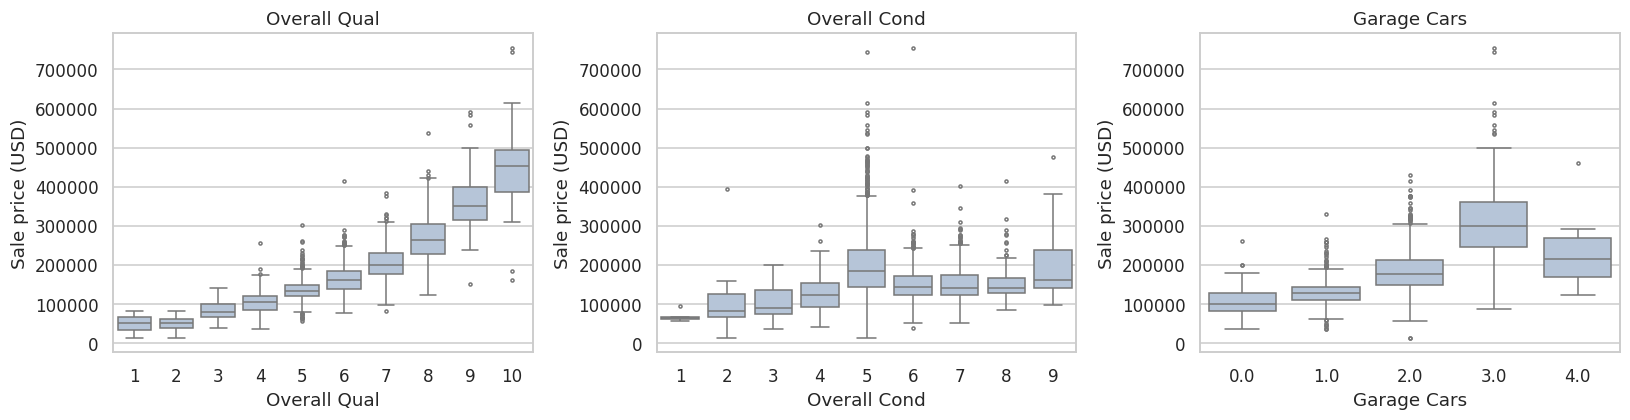

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["Overall Qual", "Overall Cond", "Garage Cars"]):
    sns.boxplot(data=eda, x=feature, y="SalePrice", ax=ax, color="lightsteelblue", fliersize=2)
    ax.set(ylabel="Sale price (USD)", title=feature)
finish_figure("02_quality_condition_garage")
for feature in ["Overall Qual", "Overall Cond", "Garage Cars"]:
    print(f"\n{feature}: counts and median prices")
    display(eda.groupby(feature, dropna=False)["SalePrice"].agg(["count", "median"]))

## 5. Bedrooms and bathrooms
Room counts do not uniquely determine house value. A larger number of bedrooms may occur in older or lower-quality homes, and several bedrooms can share a modest total area. Keep full and half bathrooms separate; these columns exclude basement bathrooms.

               count    median
Bedroom AbvGr                 
0                  5  260000.0
1                 89  155000.0
2                611  140500.0
3               1268  165000.0
4                318  183500.0
5                 38  182000.0
6                 14  146476.5
8                  1  200000.0
           count    median
Full Bath                 
0             10  150831.0
1           1073  131000.0
2           1209  193879.0
3             49  290000.0
4              3  269500.0
           count    median
Half Bath                 
0           1494  144000.0
1            831  187000.0
2             19  165150.0


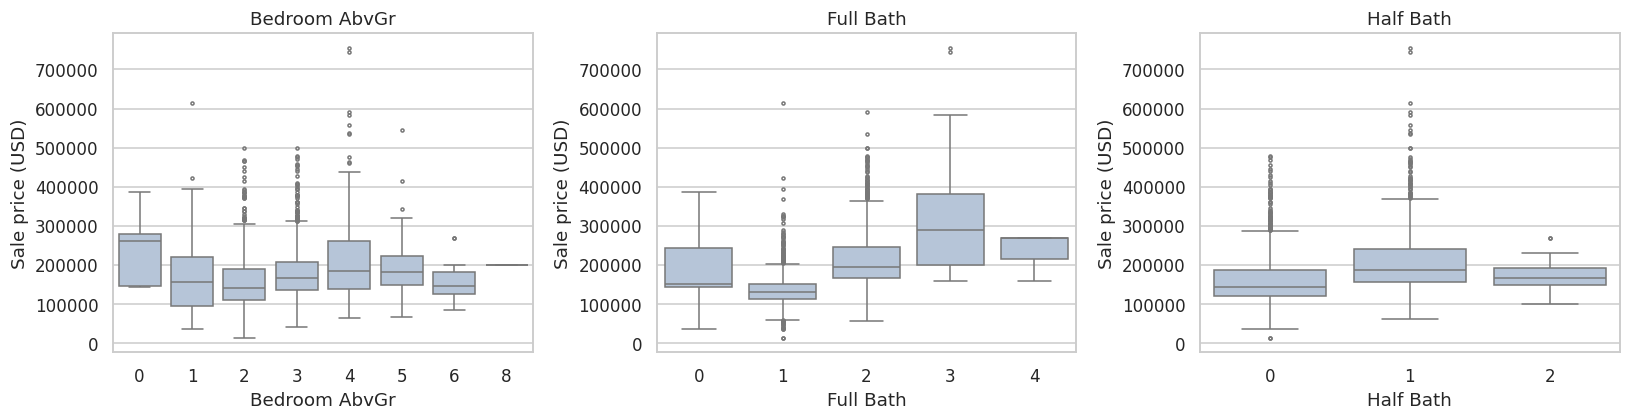

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["Bedroom AbvGr", "Full Bath", "Half Bath"]):
    sns.boxplot(data=eda, x=feature, y="SalePrice", ax=ax, color="lightsteelblue", fliersize=2)
    ax.set(ylabel="Sale price (USD)", title=feature)
finish_figure("02_bedrooms_bathrooms")
for feature in ["Bedroom AbvGr", "Full Bath", "Half Bath"]:
    display(eda.groupby(feature)["SalePrice"].agg(["count", "median"]))

## 6. Neighbourhood differences
Rank neighbourhoods by their training median price and show the number of observations. Medians in small groups are less stable. Location may proxy for many unmeasured characteristics. Unknown neighbourhoods will need explicit handling in preprocessing and the app. Rankings from the whole training set are for description only; any target-based encoding would have to be fitted within each cross-validation fold.

              count    median      mean
Neighborhood                           
MeadowV          28   90750.0   97684.0
BrDale           24  106000.0  105448.0
IDOTRR           73  107000.0  103189.0
OldTown         199  119164.0  124756.0
BrkSide          84  123950.0  124204.0
Blueste           7  124000.0  132429.0
Edwards         150  125000.0  131545.0
Sawyer          119  136000.0  135820.0
Landmrk           1  137000.0  137000.0
SWISU            37  140000.0  143120.0
NAmes           367  140000.0  145625.0
NPkVill          15  142500.0  140440.0
Mitchel          97  152500.0  157582.0
SawyerW          98  179550.0  182919.0
NWAmes          109  180000.0  186082.0
Gilbert         138  181444.0  190888.0
Blmngtn          23  187687.0  193132.0
Crawfor          89  198000.0  201150.0
ClearCr          35  200000.0  210604.0
CollgCr         211  200141.0  200845.0
Greens            7  206000.0  194321.0
Somerst         136  220500.0  226001.0
Timber           59  228000.0  240096.0


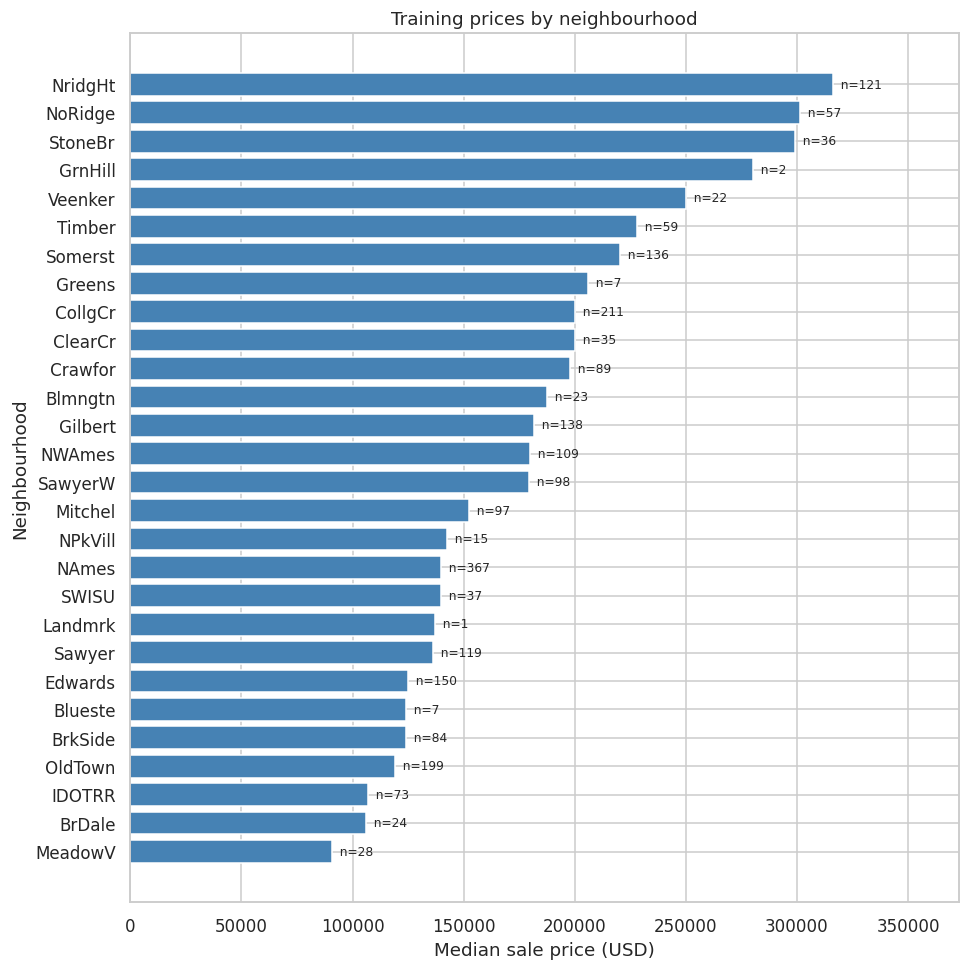

In [6]:
neighborhood_summary = eda.groupby("Neighborhood")["SalePrice"].agg(["count", "median", "mean"]).sort_values("median")
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(neighborhood_summary.index, neighborhood_summary["median"], color="steelblue")
for i, row in enumerate(neighborhood_summary.itertuples()):
    ax.text(row.median, i, f"  n={row.count}", va="center", fontsize=8)
ax.set(xlabel="Median sale price (USD)", ylabel="Neighbourhood", title="Training prices by neighbourhood")
ax.margins(x=.18)
finish_figure("02_neighborhood")
display(neighborhood_summary.round(0))

## 7. Correlations among candidate numeric features
Pearson correlation summarises linear associations. Spearman correlation summarises monotonic rank associations and helps compare ordinal variables. Neither establishes causation or detects every useful relationship. Do not include identifiers as numeric predictors or drop useful inputs solely because of a correlation threshold.

               pearson  spearman
Overall Qual     0.795     0.798
Gr Liv Area      0.698     0.712
Garage Cars      0.644     0.691
Full Bath        0.542     0.632
Half Bath        0.285     0.336
Bedroom AbvGr    0.149     0.193
Overall Cond    -0.104    -0.172
AgeAtSale       -0.546    -0.663


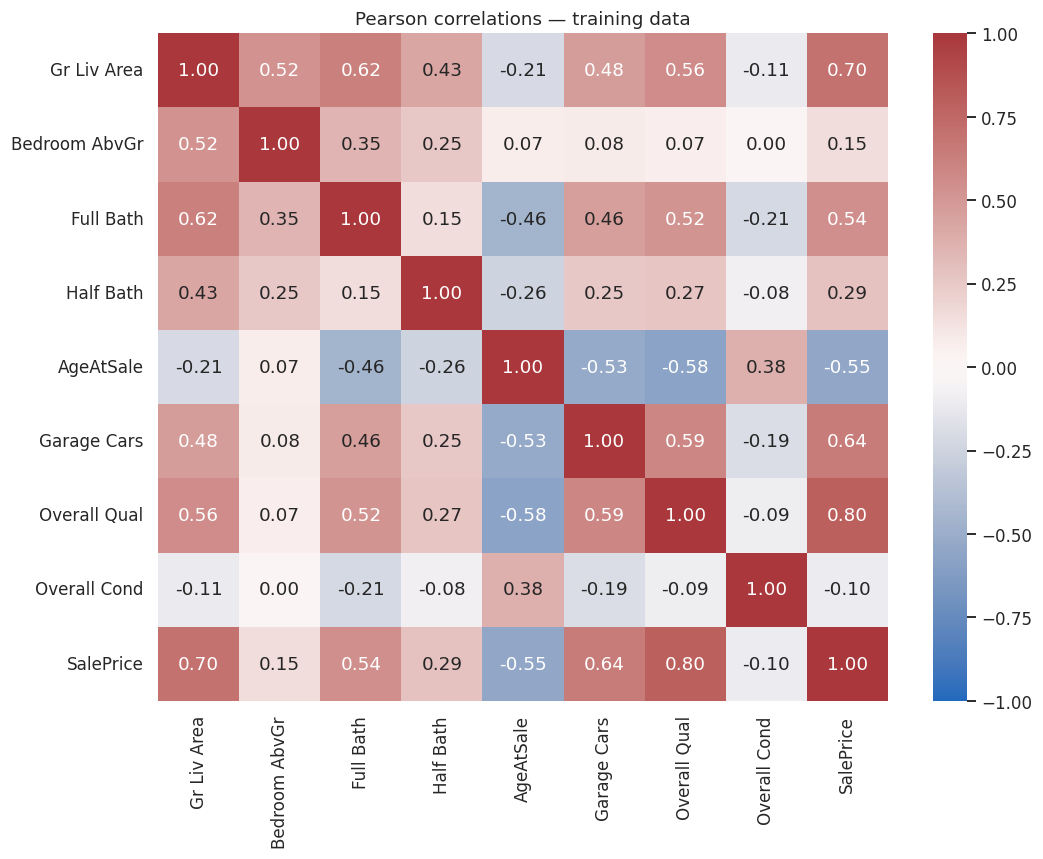

In [7]:
numeric_features = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath",
                    "AgeAtSale", "Garage Cars", "Overall Qual", "Overall Cond", "SalePrice"]
pearson = eda[numeric_features].corr(method="pearson")
spearman = eda[numeric_features].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlations — training data")
finish_figure("02_correlations")
correlation_summary = pd.DataFrame({"pearson": pearson["SalePrice"], "spearman": spearman["SalePrice"]}).drop("SalePrice")
display(correlation_summary.sort_values("pearson", ascending=False).round(3))

## 8. Missingness and explicit absence
Our parser preserves the string `NA`. In some categorical columns it represents the absence of an amenity rather than an unknown value. Missingness counts alone cannot determine the correct treatment. Notebook 3 will use the data dictionary to distinguish absence, unknown categories and numeric imputation. Imputation statistics must be learned within training folds.

                missing  literal_NA  missing_percent
Lot Frontage        393           0        16.766212
Garage Yr Blt       122           0         5.204778
Mas Vnr Type         19           0         0.810580
Mas Vnr Area         19           0         0.810580
Bsmt Exposure         3          60         0.127986
Garage Finish         2         120         0.085324
BsmtFin Type 2        2          60         0.085324
Garage Qual           1         121         0.042662
Garage Cond           1         121         0.042662
Bsmt Qual             1          60         0.042662
Bsmt Cond             1          60         0.042662
BsmtFin Type 1        1          60         0.042662
BsmtFin SF 1          1           0         0.042662
BsmtFin SF 2          1           0         0.042662
Bsmt Unf SF           1           0         0.042662
Total Bsmt SF         1           0         0.042662
Bsmt Full Bath        1           0         0.042662
Bsmt Half Bath        1           0         0.

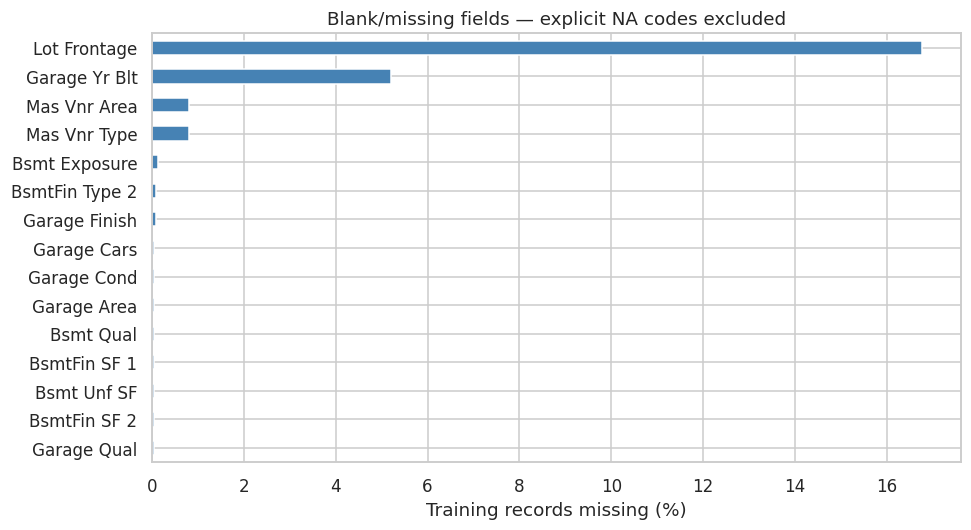

In [8]:
missingness = pd.DataFrame({"missing": eda.isna().sum(), "literal_NA": eda.eq("NA").sum()})
missingness["missing_percent"] = missingness["missing"] / len(eda) * 100
relevant = missingness[(missingness["missing"] > 0) | (missingness["literal_NA"] > 0)]
display(relevant.sort_values(["missing", "literal_NA"], ascending=False))
if relevant["missing"].sum() > 0:
    relevant["missing_percent"].sort_values().tail(15).plot.barh(figsize=(9, 5), color="steelblue")
    plt.xlabel("Training records missing (%)")
    plt.title("Blank/missing fields — explicit NA codes excluded")
    finish_figure("02_missingness")

## 9. Unusual observations and temporal coverage
Review large houses, inconsistent dates and unusually high/low prices. The 4,000 sq ft threshold is an investigation flag, not a deletion instruction. Do not remove observations based on test errors. If exclusion is justified later, document its domain basis and retain an honest evaluation population.

Annual counts and medians describe coverage, not a pure market trend: the mix of houses sold changes by year. Our random holdout evaluates the same historical population; future forecasting would require a temporal evaluation design.

In [9]:
review_columns = ["PID", "Gr Liv Area", "SalePrice", "Overall Qual", "Neighborhood", "Sale Condition", "Year Built", "Yr Sold"]
review_mask = eda["Gr Liv Area"].gt(4000) | eda["AgeAtSale"].lt(0)
review_records = eda.loc[review_mask, review_columns].copy()
display(review_records)
print("Lowest and highest recorded training prices:")
display(pd.concat([eda.nsmallest(3, "SalePrice"), eda.nlargest(3, "SalePrice")])[review_columns])
annual_summary = eda.groupby("Yr Sold")["SalePrice"].agg(["count", "median"])
display(annual_summary)
print("Sale conditions:")
display(eda["Sale Condition"].value_counts().to_frame("count"))

            PID  Gr Liv Area  SalePrice  Overall Qual Neighborhood Sale Condition  Year Built  Yr Sold
1197  908154235         5642     160000            10      Edwards        Partial        2008     2008
1412  528320050         4476     745000            10      NoRidge        Abnorml        1996     2007
1418  528351010         4316     755000            10      NoRidge         Normal        1994     2007
1747  908154195         5095     183850            10      Edwards        Partial        2008     2007
Lowest and highest recorded training prices:
            PID  Gr Liv Area  SalePrice  Overall Qual Neighborhood Sale Condition  Year Built  Yr Sold
146   902207130          832      12789             2      OldTown        Abnorml        1923     2010
1243  910251050          733      13100             1       IDOTRR        Abnorml        1952     2008
577   902477120          720      34900             4       IDOTRR        Abnorml        1920     2009
1418  528351010         4316

## 10. Evidence summary and modelling implications
The following text is generated from this training partition so the findings stay aligned when the notebook is rerun. Correlation rankings apply only to the selected numeric inputs; they do not rank the predictive value of categorical location or establish causal importance.

In [10]:
top = correlation_summary["spearman"].abs().sort_values(ascending=False).head(3).index.tolist()
findings = [
    f"Training population: {len(eda):,} historical sales; holdout not examined.",
    f"Median price: ${eda['SalePrice'].median():,.0f}; mean: ${eda['SalePrice'].mean():,.0f}.",
    f"Price skewness: {eda['SalePrice'].skew():.2f}; log1p skewness: {eda['LogSalePrice'].skew():.2f}.",
    "Largest absolute Spearman associations among selected numeric inputs: " + ", ".join(top) + ".",
    f"Neighbourhoods represented: {len(neighborhood_summary)}; groups with fewer than 20 sales: {(neighborhood_summary['count'] < 20).sum()}.",
    f"Large-area/date records flagged for review: {len(review_records)}; no rows removed.",
]
print("\n".join(findings))
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
neighborhood_summary.to_csv(REPORTS_DIR / "eda_neighborhood_summary.csv")
correlation_summary.to_csv(REPORTS_DIR / "eda_correlations.csv")
missingness.to_csv(REPORTS_DIR / "eda_missingness.csv")
review_records.to_csv(REPORTS_DIR / "eda_review_records.csv", index=False)
annual_summary.to_csv(REPORTS_DIR / "eda_annual_summary.csv")
(REPORTS_DIR / "eda_findings.txt").write_text("\n".join(findings), encoding="utf-8")
print("Saved EDA figures and summary tables; original partitions remain unchanged.")

Training population: 2,344 historical sales; holdout not examined.
Median price: $160,000; mean: $178,582.
Price skewness: 1.75; log1p skewness: -0.09.
Largest absolute Spearman associations among selected numeric inputs: Overall Qual, Gr Liv Area, Garage Cars.
Neighbourhoods represented: 28; groups with fewer than 20 sales: 5.
Large-area/date records flagged for review: 4; no rows removed.
Saved EDA figures and summary tables; original partitions remain unchanged.


## 11. Handover to Notebook 3
- Retain the original partitions and exclude `Order` and `PID` from predictors.
- Define the app feature schema, including age at sale and explicit area/bathroom units.
- Interpret absence codes using the source dictionary; fit imputers and encoders within pipelines.
- Compare models using the requested core inputs and, where appropriate, an expanded quality/condition feature set.
- Consider log-target modelling as a candidate and compare cross-validation MAE in USD.
- Keep flagged observations until a documented decision is justified; do not make blanket deletions.
- Treat sparse categories and unseen neighbourhoods explicitly.

Detailed exploration informs candidate choices but is not an unbiased estimate of model performance. Notebook 4 will use cross-validation for selection; Notebook 5 will provide final holdout evaluation.

**Completed:** training-only exploratory analysis. **Next:** preprocessing and feature engineering.